# Cobalt Straits Ferry: which car reservations to oversell
**Team Fantastic Four · ISM6930 Final Project · Checkpoint notebook (after Project lab 4)**

Scenario 01. The decision: at 2 p.m. the day before, put a reservation on the **oversell list** (1 = release its lane to standby) or keep its lane (0).

**AI-use note** *(team to complete)*: tools used, what we used them for, and how we checked the key results (for example: we recomputed the no-model cost and today's-rule cost by hand from the outcome counts).

**How to run:** upload `train.csv`, `test.csv`, `holdout_features.csv` to Colab's Files pane, then *Runtime → Run all*. Everything uses `random_state=42`.

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import make_scorer, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

RS = 42
np.random.seed(RS)

train_raw = pd.read_csv("train.csv")
test_raw = pd.read_csv("test.csv")
holdout_raw = pd.read_csv("holdout_features.csv")
print("train", train_raw.shape, "| test", test_raw.shape, "| holdout", holdout_raw.shape)

train (6120, 19) | test (2000, 19) | holdout (2000, 17)


# Part 1. Business understanding  *(Project lab 1)*

## 1.1 The problem in our words
Cobalt Straits Ferry lets customers reserve car lanes for free, and about one reserved car in six never shows up. When a no-show's lane is kept, it sails empty and the fare is lost. When a lane is released to the standby line and the car turns up anyway, the car is bumped, which costs money and goodwill, especially with island residents.

- **Stakeholders:** Dana Whitcomb (revenue, wants more overselling), Ruth Calloway (terminal operations, worried about bumping island families), Captain Navarro (believes wind keeps day-trippers home), Joanne Pryce (GM, decides the rule).
- **Decision our model informs:** for every reservation on tomorrow's sailings, at 2 p.m. the day before: put it on the oversell list or not.
- **Today's rule:** on a sailing forecast at 25 knots or more, every *visitor* reservation *without* a prepaid fare goes on the list.

## 1.2 What each outcome costs

| Outcome | What happens | Cost to Cobalt | Source in the brief |
|---|---|---|---|
| **Kept lane, car is a no-show** (missed no-show) | Lane sails empty | **$91** lost fare | Dana: average one-way fare $91, "the $91 is simply gone" |
| **Listed, car turns up** (bump) | $150 travel credit + free guaranteed place on next sailing, which pushes a standby car off | **$150 + $85 = $235** | Ruth: $150 credit, "call it another $85" |
| **Listed, car is a no-show** (correct oversell) | Lane sold to standby | $0 (saves the $91 above) | Dana; the season's standby lines fill any released lane |
| **Kept lane, car shows** (correct keep) | Normal sailing | $0 | — |

**Non-dollar cost:** every bump of an island resident is a story at the selectboard (Ruth). So we also count **bumped cars** and **bumped island residents**.

**Our measure:** total cost = $91 × missed no-shows + $235 × bumps, reported as **dollars per 1,000 reservations** (lower is better). We do not use accuracy: a model that lists nobody is 84% accurate and saves nothing. Because a bump costs 2.6 times a miss, listing a reservation only pays when its no-show chance is above **235 / (235 + 91) ≈ 72%**.

*Judgment call:* a prepaid customer already paid, but releasing their lane still earns a standby fare and bumping them still costs the credit plus the displaced car, so we use the same two figures for them.

In [ ]:
COST_MISS = 91            # Dana: lane sails empty
COST_BUMP = 150 + 85      # Ruth: travel credit + displaced standby fare
BREAKEVEN = COST_BUMP / (COST_BUMP + COST_MISS)
SEASON_RESERVATIONS = 142_000   # brief: summer season, when Cobalt oversells

def business_cost(y_true, decision):
    y_true = np.asarray(y_true); decision = np.asarray(decision)
    missed = ((decision == 0) & (y_true == 1)).sum()
    bumped = ((decision == 1) & (y_true == 0)).sum()
    return missed * COST_MISS + bumped * COST_BUMP

def cost_per_1000(y_true, decision):
    return business_cost(y_true, decision) / len(y_true) * 1000

print(f"Bump cost ${COST_BUMP}, miss cost ${COST_MISS}, break-even no-show chance = {BREAKEVEN:.3f}")

Bump cost $235, miss cost $91, break-even no-show chance = 0.721


## 1.3 The bar to clear
Three ways to decide without a model:
- **List nobody** (Cobalt hardly oversells today outside the wind rule): every no-show sails empty.
- **List everybody**: makes no sense here. 84% of cars show up, so it would bump thousands of cars. We show it only to prove the point.
- **Today's rule** (wind ≥ 25 kt, visitor, not prepaid).

A model must beat the **best** of these on the test set to be worth deploying.

In [ ]:
def todays_rule(df):
    return ((df["forecast_wind_kt"] >= 25) & (df["trip_purpose"].str.strip().str.lower() == "visitor")
            & (df["fare_prepaid"] == 0)).astype(int)

def baseline_table(df, name):
    y = df["no_show"]
    rows = []
    for label, dec in [("List nobody", np.zeros(len(df), int)),
                       ("List everybody", np.ones(len(df), int)),
                       ("Today's rule", todays_rule(df))]:
        dec = np.asarray(dec)
        rows.append({"set": name, "rule": label, "listed": dec.sum(),
                     "bumped": ((dec == 1) & (y == 0)).sum(),
                     "missed no-shows": ((dec == 0) & (y == 1)).sum(),
                     "$ per 1,000": round(cost_per_1000(y, dec))})
    return pd.DataFrame(rows)

bars = pd.concat([baseline_table(train_raw.drop_duplicates(), "train"), baseline_table(test_raw, "test")])
bars

,set,rule,listed,bumped,missed no-shows,"$ per 1,000"
0,train,List nobody,0,0,946,14348
1,train,List everybody,6000,5054,0,197948
2,train,Today's rule,312,147,781,17603
0,test,List nobody,0,0,316,14378
1,test,List everybody,2000,1684,0,197870
2,test,Today's rule,97,48,267,17788


**What this shows.** Today's rule flags about 1 reservation in 20, and about half of those cars turn up anyway (Joanne's numbers check out). Because a bump costs $235 and a saved lane only $91, half-right is not good enough: **today's rule costs more than listing nobody**. So the bar to beat is **"list nobody"**, about $14,400 per 1,000 reservations on the test set.

## 1.4 Success criteria
- Cost per 1,000 reservations clearly below "list nobody" on cross-validation, by more than the spread across folds.
- Report bumped cars and **bumped island residents** next to the dollars, since the selectboard will ask (Ruth).
- A list size the reservations office can handle at 2 p.m. (a list, not a manual review, so capacity is not tight).
- If no model clearly beats "list nobody", our recommendation is *do not deploy*.

# Part 2. Data exploration and preparation  *(Project lab 1)*
## 2.1 What is wrong with the data

In [ ]:
# Prompt: Write python code using pandas to explore the `train_raw` and `test_raw` datasets and print the following specific details:
# 1. The number of duplicate rows in both train and test sets.
# 2. The columns with missing values in the train set and their counts.
# 3. The number of unique spellings of 'vehicle_type', along with a sorted list of the first 10 unique values.
# 4. The unique values in the 'passengers' column.
# 5. The count of rows where 'vehicle_length_ft' is strictly greater than 80, and a check of whether all those values are divisible by 12.
# Code in chat, not in notebook.
6. The mean 'no_show' rate grouped by whether the 'checkin_lane' column is missing (null) or not.
print("Duplicate rows in train:", train_raw.duplicated().sum(), "| in test:", test_raw.duplicated().sum())
print("\nMissing values (train):"); print(train_raw.isna().sum()[train_raw.isna().sum() > 0])
print("\nvehicle_type spellings:", train_raw["vehicle_type"].nunique(), "->", sorted(train_raw["vehicle_type"].unique())[:10], "...")
print("\npassengers values:", train_raw["passengers"].unique())
print("\nvehicle_length_ft above 80 ft:", (train_raw["vehicle_length_ft"] > 80).sum(),
      "| all divisible by 12:", (train_raw.loc[train_raw["vehicle_length_ft"] > 80, "vehicle_length_ft"] % 12 == 0).all())
print("\nNo-show rate by whether checkin_lane is blank:")
print(train_raw.groupby(train_raw["checkin_lane"].isna())["no_show"].mean())

Duplicate rows in train: 120 | in test: 0

Missing values (train):
prior_bookings_24m    1315
prior_no_shows_24m    1315
forecast_rain_pct      310
checkin_lane           998
dtype: int64

vehicle_type spellings: 30 -> ['CAR', 'CAR WITH TRAILER', 'CAR_WITH_TRAILER', 'Car', 'Car With Trailer', 'Car_With_Trailer', 'MOTORCYCLE', 'Motorcycle', 'PICKUP', 'Pickup'] ...

passengers values: ['3' '2' '1' 'unknown' '5' '4' '7' '6']

vehicle_length_ft above 80 ft: 49 | all divisible by 12: True

No-show rate by whether checkin_lane is blank:
checkin_lane
False    0.000000
True     0.966934
Name: no_show, dtype: float64


Explanation:
1. 120 exact duplicate rows in train (same reservation number twice). Duplicates would count one reservation twice and leak between CV folds, so I dropped them.
2. `vehicle_type` has 30 spellings of 6 types (`CAR`, `car `, `Suv Van`...), so I fixed them using trim  to remove leading and trailing whitespaces, converting all characters to lower case, and replacing spaces with underscores.
3. `passengers` contains the text `unknown`, so I treated it as missing, and then filled it with the training median.
4. `vehicle_length_ft` has impossible values up to 396 ft (the biggest ship carries 58 cars). Every value above 80 is divisible by 12, which means these were typed in inches, so I divided them by 12.
5. `checkin_lane` is leakage. It is recorded at check-in on the day of sailing after our 2 pm decision. A blank lane means "did not check in", which is the outcome (97% no-show), so I dropped it.
6. `prior_bookings_24m` / `prior_no_shows_24m` blank is guest booking with no account. The blank itself is information (guests no-show far more), so I kept a `guest` flag and filled with the training median.
7. `forecast_rain_pct` blank is where the nightly copy failed (not the customer's doing), so I filled with the training median and kept a missing flag.

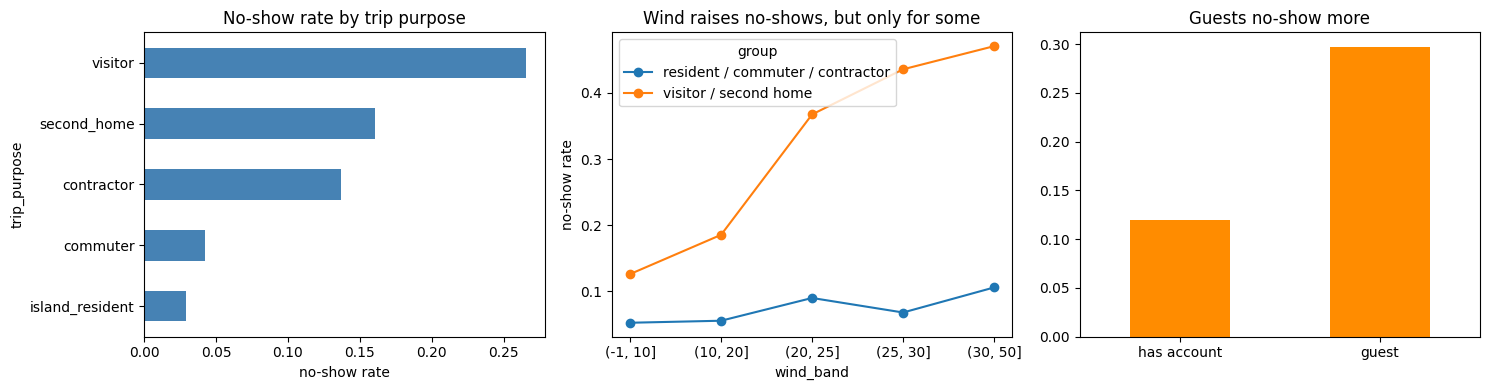

No-show rate, prepaid vs not: {0: 0.158, 1: 0.153}


In [ ]:
# Prompt: Write python code using pandas, matplotlib, and numpy to analyze the `train_raw` dataset and generate a 1-row, 3-column subplot figure (size 15x4) along with a printed metric:
# 1. First Subplot (axes[0]): Plot a horizontal bar chart of the average 'no_show' rate grouped by 'trip_purpose' (sorted in ascending order), colored in 'steelblue'. Title it 'No-show rate by trip purpose' and label the x-axis 'no-show rate'.
# 2. Second Subplot (axes[1]): Bin the 'forecast_wind_kt' column into intervals of [-1, 10, 20, 25, 30, 50] under a new column 'wind_band'. Create a grouping column 'group' that maps 'visitor' and 'second_home' to 'visitor / second home' and all other purposes to 'resident / commuter / contractor'.
# Plot a line chart with marker 'o' of 'no_show' rate across 'wind_band' grouped by 'group'. Title it 'Wind raises no-shows, but only for some' and label the y-axis 'no-show rate'.
# 3. Third Subplot (axes[2]): Plot a vertical bar chart showing the mean 'no_show' rate grouped by whether 'prior_bookings_24m' is missing (labeling False as 'has account' and True as 'guest'), colored in 'darkorange'. Title it 'Guests no-show more' and rotate the x-axis tick labels to 0.
# Show code in chat, not in notebook.

Apply plt.tight_layout() and show the figure. Finally, group the dataset by 'fare_prepaid', calculate the mean 'no_show' rate rounded to 3 decimal places, convert it to a dictionary, and print it with the label 'No-show rate, prepaid vs not:'.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train_raw.groupby("trip_purpose")["no_show"].mean().sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("No-show rate by trip purpose"); axes[0].set_xlabel("no-show rate")

tmp = train_raw.assign(wind_band=pd.cut(train_raw["forecast_wind_kt"], [-1, 10, 20, 25, 30, 50]),
                       group=np.where(train_raw["trip_purpose"].isin(["visitor", "second_home"]), "visitor / second home", "resident / commuter / contractor"))
tmp.pivot_table("no_show", "wind_band", "group", observed=True).plot(ax=axes[1], marker="o")
axes[1].set_title("Wind raises no-shows, but only for some"); axes[1].set_ylabel("no-show rate")

train_raw.groupby(train_raw["prior_bookings_24m"].isna())["no_show"].mean().rename({False: "has account", True: "guest"}).plot.bar(ax=axes[2], color="darkorange")
axes[2].set_title("Guests no-show more"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print("No-show rate, prepaid vs not:", train_raw.groupby("fare_prepaid")["no_show"].mean().round(3).to_dict())

Explanation:
1. Wind and trip purpose:
- The data supports Captain Navarro's observation that weather affects different customers differently. Visitors and people who own multiple homes are more likely to miss their trips when strong winds are forecast, while island residents and commuters are more likely to travel regardless of the weather. This suggests that our model should consider wind conditions and trip purpose together.
2. Prepaid status:
- The current policy assumes that customers who have prepaid are more likely to show up. However, our data shows that prepaid and non-prepaid customers have nearly the same no-show rates, suggesting that prepaid status alone may not be a strong predictor of whether someone will show up.
3. Island residents:
- Our data shows that island residents have a very low no-show rate of approximately 3%, meaning they are much more likely to show up for their reservations. Therefore, the model should be careful about placing their reservations on the oversell list to avoid disrupting residents' daily travel.

4. Changes in the holdout data:
- The later-season holdout data differs from the historical data in three ways: the booking window increased from 90 to 120 days, app reservations increased from approximately 20% to 34%, and windy conditions became more common. These changes could affect customer behavior and make the model less reliable, so we should consider them when evaluating its potential performance in the later season.

In [ ]:
# Prompt: Compare the training and holdout datasets to see whether there are any changes in the booking window, average forecast wind speed, and percentage of reservations made through the app.
# Display the results in a table rounded to two decimal places.
# Show code in chat, not in notebook.
shift = pd.DataFrame({
    "train": [train_raw["lead_time_days"].max(), train_raw["forecast_wind_kt"].mean(), (train_raw["booking_channel"] == "app").mean()],
    "holdout": [holdout_raw["lead_time_days"].max(), holdout_raw["forecast_wind_kt"].mean(), (holdout_raw["booking_channel"] == "app").mean()]},
    index=["max lead time (days)", "mean forecast wind (kt)", "share booked in app"]).round(2)
shift

,train,holdout
max lead time (days),90.00,120.00
mean forecast wind (kt),15.12,18.16
share booked in app,0.17,0.34


## 2.2 – 2.3 Preparation and features
Explanation:
- I cleaned all three datasets using the same predefined rules to keep the data consistent. This includes standardizing text values, correcting vehicle lengths that appear to be recorded in inches, and converting unknown passenger counts into missing values. I also removed duplicate records from the training data.

- Next, I create several features based on business logic. These include identifying customers with no booking history (guest), calculating each customer's previous no-show rate (prior_no_show_rate), identifying windy conditions of 25 knots or higher (windy_25), and capturing how wind may affect visitors and second-home owners differently (leisure_wind). I also applied a logarithmic transformation to booking lead time (log_lead) because booking times vary widely.

- The cleaning function only applies predefined rules and does not learn values from the data, so it can be applied consistently to all three datasets. Any learned preprocessing, such as filling missing values, scaling, and encoding categories, is handled separately inside the modeling pipeline using training data only. Finally, I removed checkin_lane because it is only available after check-in, while keeping times_modified because it is known at the 2 pm decision time. This ensures that the model only uses information available when the business makes its decision.

In [ ]:
# Prompt: Clean the training, test, and holdout datasets using consistent rules.
# Standardize categorical values, convert unknown passenger counts to missing values, correct vehicle lengths recorded in inches, and create additional features based on customer history, wind conditions, and booking lead time. Remove duplicate training records and exclude columns that are unavailable at the time of the business decision.
# Finally, separate the predictors from the target variable and display basic information about the cleaned training data.
# Show code in chat, not in notebook.
CAT_COLS = ["route", "sailing_weekday", "trip_purpose", "booking_channel", "vehicle_type"]

def clean(df):
    d = df.copy()
    d["vehicle_type"] = d["vehicle_type"].str.strip().str.lower().str.replace(" ", "_")
    d["trip_purpose"] = d["trip_purpose"].str.strip().str.lower()
    d["passengers"] = pd.to_numeric(d["passengers"].replace("unknown", np.nan))
    inches = d["vehicle_length_ft"] > 80
    d.loc[inches, "vehicle_length_ft"] = d.loc[inches, "vehicle_length_ft"] / 12
    d["guest"] = d["prior_bookings_24m"].isna().astype(int)
    d["prior_no_show_rate"] = d["prior_no_shows_24m"] / d["prior_bookings_24m"]
    d["windy_25"] = (d["forecast_wind_kt"] >= 25).astype(int)
    d["leisure_wind"] = d["trip_purpose"].isin(["visitor", "second_home"]) * d["forecast_wind_kt"]
    d["log_lead"] = np.log1p(d["lead_time_days"])
    return d.drop(columns=["checkin_lane"], errors="ignore")

train = clean(train_raw.drop_duplicates())
test = clean(test_raw)
holdout = clean(holdout_raw)

X_train = train.drop(columns=["id", "no_show"]); y_train = train["no_show"]
X_test = test.drop(columns=["id", "no_show"]);   y_test = test["no_show"]
NUM_COLS = [c for c in X_train.columns if c not in CAT_COLS]
print("train rows after dropping duplicates:", len(train), "| no-show rate:", round(y_train.mean(), 3))
print("vehicle types now:", sorted(X_train["vehicle_type"].unique()))
print("max length now:", X_train["vehicle_length_ft"].max(), "ft")

train rows after dropping duplicates: 6000 | no-show rate: 0.158
vehicle types now: ['car', 'car_with_trailer', 'motorcycle', 'pickup', 'rv', 'suv_van']
max length now: 36 ft


## 2.4 Leakage
Explanation:
- I removed checkin_lane because it is only available after the business has made its decision. I also removed duplicate records before cross-validation to prevent the same reservation from appearing in both training and validation folds.
- Missing-value imputation, scaling, and one-hot encoding are placed inside the pipeline so they are learned from the training data in each fold only, without using information from the test or holdout sets.
- Finally, I keep the test set separate and use it only once, at the end of Part 4, to evaluate the selected model.

In [ ]:
# Prompt: Create a preprocessing function that handles missing numerical values using the median, adds indicators for missing values, and standardizes numerical features.
# For categorical features, apply one-hot encoding and safely handle categories that may appear in new data but were not present during training.
# Show code in chat, not in notebook.
def make_p
reprocessor():
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scale", StandardScaler())])
    return ColumnTransformer([("num", num, NUM_COLS),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])

# Part 3. Model development  *(Project labs 1 – 3)*

**How we compare families fairly.** Same cleaned training rows, same 5-fold stratified cross-validation (`random_state=42`), same preprocessing pipeline, same measure.

For every model we search a small grid with `GridSearchCV`. The score is our business measure: **cost per 1,000 reservations at the best cut-off in that fold** (we try cut-offs from 0.30 to 0.95). We use the best cut-off because families produce probabilities on different scales (KNN and SVM probabilities are rough), and the business only cares what the *list* costs. Picking the cut-off inside each fold is slightly optimistic, but equally so for every family; the final cut-off is chosen once on the training rows and then tested once.

We do **not** use class weights: they would push probabilities away from the real no-show chance, and the cost-based cut-off already handles the imbalance.

In [ ]:
CUTOFFS = np.round(np.arange(0.30, 0.96, 0.01), 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def best_cutoff(y_true, proba):
    costs = [cost_per_1000(y_true, (proba >= c).astype(int)) for c in CUTOFFS]
    i = int(np.argmin(costs))
    return CUTOFFS[i], costs[i]

def neg_cost_score(estimator, X, y):
    proba = estimator.predict_proba(X)[:, 1]
    return -best_cutoff(y, proba)[1]

results = {}   # family -> fitted GridSearchCV

def run_family(name, model, grid):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    gs = GridSearchCV(pipe, {f"model__{k}": v for k, v in grid.items()}, scoring=neg_cost_score, cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    results[name] = gs
    i = gs.best_index_
    fold_costs = [-gs.cv_results_[f"split{k}_test_score"][i] for k in range(5)]
    print(f"{name:22s} best {gs.best_params_}  ->  ${np.mean(fold_costs):,.0f} per 1,000 (± {np.std(fold_costs):,.0f})")
    return None

## 3.1 Reference model
**List nobody** is the business's real alternative (Part 1.3). As a model reference we also fit a `DummyClassifier` (predicts the base rate for everyone, so it never clears 72% and lists nobody), and **logistic regression** as the simple model every complex one must beat.

In [ ]:
null_folds = [cost_per_1000(y_train.iloc[v], np.zeros(len(v), int)) for _, v in cv.split(X_train, y_train)]
print(f"List nobody            ${np.mean(null_folds):,.0f} per 1,000 (± {np.std(null_folds):,.0f})")
run_family("Dummy (base rate)", DummyClassifier(strategy="prior"), {"strategy": ["prior"]})

List nobody            $14,348 per 1,000 (± 30)
Dummy (base rate)      best {'model__strategy': 'prior'}  ->  $14,348 per 1,000 (± 30)


## 3.2 Families from Module 4 and 5 (Project lab 1)
- **Logistic regression:** tune `C` (how strongly coefficients are shrunk).
- **KNN:** tune `n_neighbors` (more neighbours = smoother probabilities) and `weights`. Scaling matters for KNN, which the pipeline handles.
- **SVM (RBF kernel):** tune `C` and `gamma`. `probability=True` gives a no-show chance we can put a cut-off on.

In [ ]:
run_family("Logistic regression", LogisticRegression(max_iter=3000), {"C": [0.01, 0.1, 1, 10]})
run_family("KNN", KNeighborsClassifier(), {"n_neighbors": [25, 50, 100], "weights": ["uniform", "distance"]})
run_family("SVM (RBF)", SVC(probability=True, random_state=RS), {"C": [0.3, 1, 3], "gamma": ["scale", 0.01]})

Logistic regression    best {'model__C': 0.01}  ->  $12,569 per 1,000 (± 476)
KNN                    best {'model__n_neighbors': 50, 'model__weights': 'distance'}  ->  $12,188 per 1,000 (± 439)
SVM (RBF)              best {'model__C': 0.3, 'model__gamma': 0.01}  ->  $11,590 per 1,000 (± 529)


## 3.3 Trees, forests and boosting (Project lab 2)
- **Decision tree:** tune `max_depth` and `min_samples_leaf` (a leaf needs enough reservations to give a trustworthy no-show rate).
- **Random forest:** 300 trees; tune `min_samples_leaf` and `max_features`.
- **Gradient boosting** (scikit-learn) with **early stopping** (`n_iter_no_change=20`, 20% of each training fold held back): tune `learning_rate` and `max_depth`.

In [ ]:
run_family("Decision tree", DecisionTreeClassifier(random_state=RS),
           {"max_depth": [3, 5, 7], "min_samples_leaf": [20, 50, 100]})
run_family("Random forest", RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1),
           {"min_samples_leaf": [2, 5, 10], "max_features": ["sqrt", 0.5]})
run_family("Gradient boosting", GradientBoostingClassifier(n_estimators=1000, n_iter_no_change=20, validation_fraction=0.2, random_state=RS),
           {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, 4]})

Decision tree          best {'model__max_depth': 3, 'model__min_samples_leaf': 20}  ->  $11,749 per 1,000 (± 432)
Random forest          best {'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}  ->  $11,132 per 1,000 (± 614)
Gradient boosting      best {'model__learning_rate': 0.03, 'model__max_depth': 2}  ->  $10,994 per 1,000 (± 628)


## 3.4 Neural network (Project lab 3)
scikit-learn `MLPClassifier` with early stopping. Tune the hidden layer size and `alpha` (the penalty that keeps weights small; with only 6,000 rows a network overfits easily).

In [ ]:
run_family("Neural network (MLP)", MLPClassifier(max_iter=2000, early_stopping=True, random_state=RS),
           {"hidden_layer_sizes": [(16,), (32,), (32, 16)], "alpha": [0.1, 1.0, 3.0]})

Neural network (MLP)   best {'model__alpha': 0.1, 'model__hidden_layer_sizes': (32,)}  ->  $11,566 per 1,000 (± 735)


# Part 4. Evaluation and selection  *(Project lab 4)*
## 4.1 Every family on our measure, with the spread across folds

,model,"mean $ per 1,000",spread (std),saving vs list nobody
0,Gradient boosting,"$10,994",$628,23.4%
1,Random forest,"$11,132",$614,22.4%
2,Neural network (MLP),"$11,566",$735,19.4%
3,SVM (RBF),"$11,590",$529,19.2%
4,Decision tree,"$11,749",$432,18.1%
5,KNN,"$12,188",$439,15.0%
6,Logistic regression,"$12,569",$476,12.4%
7,List nobody (no model),"$14,348",$30,0.0%
8,Dummy (base rate),"$14,348",$30,0.0%


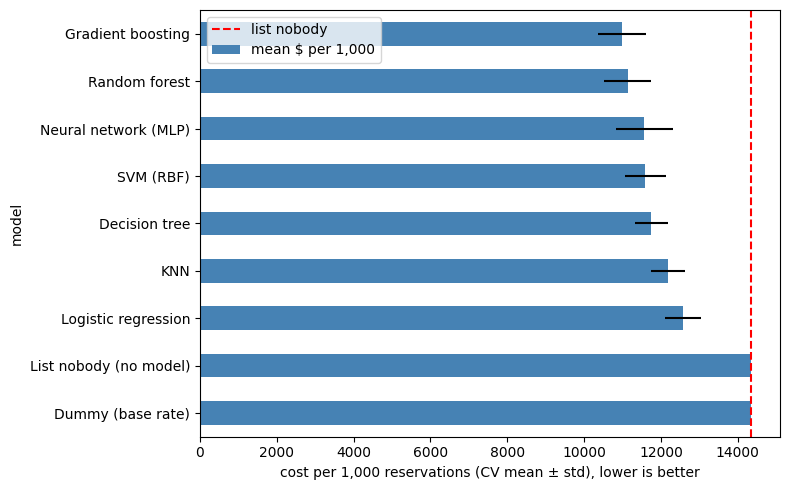

In [ ]:
rows = [{"model": "List nobody (no model)", "mean $ per 1,000": np.mean(null_folds), "spread (std)": np.std(null_folds)}]
for name, gs in results.items():
    i = gs.best_index_
    f = [-gs.cv_results_[f"split{k}_test_score"][i] for k in range(5)]
    rows.append({"model": name, "mean $ per 1,000": np.mean(f), "spread (std)": np.std(f)})
comparison = pd.DataFrame(rows).sort_values("mean $ per 1,000").reset_index(drop=True)
comparison["saving vs list nobody"] = 1 - comparison["mean $ per 1,000"] / np.mean(null_folds)
display(comparison.style.format({"mean $ per 1,000": "${:,.0f}", "spread (std)": "${:,.0f}", "saving vs list nobody": "{:.1%}"}))

ax = comparison.iloc[::-1].plot.barh(x="model", y="mean $ per 1,000", xerr="spread (std)", legend=False, figsize=(8, 5), color="steelblue")
ax.axvline(np.mean(null_folds), color="red", ls="--", label="list nobody"); ax.legend()
ax.set_xlabel("cost per 1,000 reservations (CV mean ± std), lower is better"); plt.tight_layout(); plt.show()

**Reading the table.** *(Team: check these sentences against your own run.)* Every model beats "list nobody", by roughly 12% to 23%. Gradient boosting and the random forest come out cheapest; the SVM, the network and the single tree are next; logistic regression and KNN are last. That fits Part 2: the signal is an **interaction** (wind matters for visitors but not for residents), which tree ensembles split on naturally, while logistic regression only sees it through our `leisure_wind` feature. The top two are about $140 apart while each fold-spread is about $600, so the gap between them is **within the noise**; the gap to logistic regression (about $1,500) is larger than the spread.

## 4.2 Candidate and its decision rule
The two cheapest families are within the noise, so we run a stricter check on the training rows for both. In production the office uses **one** cut-off, not a new one per fold, so we pick one cut-off on out-of-fold predictions (each training row predicted by a model that never saw it) and compare the two at that single cut-off. The cheaper one becomes the candidate.

In [ ]:
top_two = comparison[comparison["model"].isin(results)]["model"].tolist()[:2]
cutoffs, oof_cost = {}, {}
for name in top_two:
    oof = cross_val_predict(results[name].best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    c, cost = best_cutoff(y_train, oof)
    cutoffs[name], oof_cost[name] = c, cost
    print(f"{name}: best cut-off on training rows = {c:.2f}, out-of-fold cost ${cost:,.0f} per 1,000, list share {(oof >= c).mean():.1%}")
CANDIDATE, RUNNER_UP = sorted(top_two, key=oof_cost.get)
print("\nCandidate:", CANDIDATE, "| runner-up:", RUNNER_UP)
print(f"(The cost-based break-even is {BREAKEVEN:.2f}: a cut-off near it means the probabilities are well calibrated.)")

Gradient boosting: best cut-off on training rows = 0.73, out-of-fold cost $11,560 per 1,000, list share 4.3%
Random forest: best cut-off on training rows = 0.62, out-of-fold cost $11,348 per 1,000, list share 4.5%

Candidate: Random forest | runner-up: Gradient boosting
(The cost-based break-even is 0.72: a cut-off near it means the probabilities are well calibrated.)


**Why the candidate over the runner-up** *(team to finish in your own words for the final)*: compare the mean cost, the spread, how many cars each bumps, and how easy each is to explain to Joanne. If the two are within the noise, prefer the one that bumps fewer island residents or is simpler.

## 4.3 What drives the predictions
Permutation importance on the training rows: how much our business cost rises when a column is shuffled.

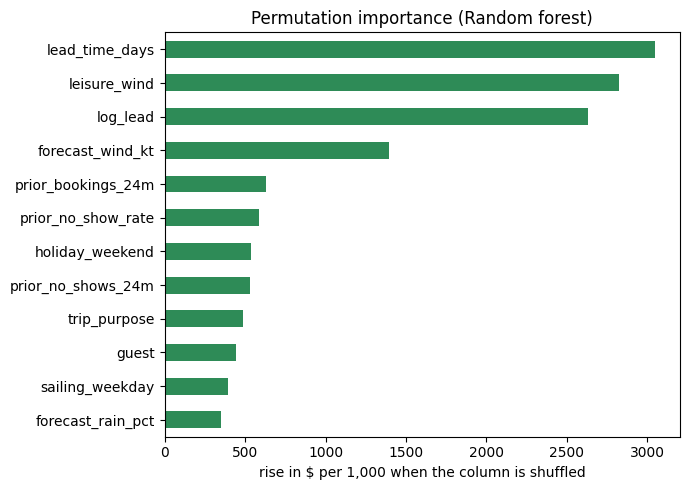

In [ ]:
final_model = results[CANDIDATE].best_estimator_
c_final = cutoffs[CANDIDATE]
def cost_scorer(est, X, y):
    return -cost_per_1000(y, (est.predict_proba(X)[:, 1] >= c_final).astype(int))
imp = permutation_importance(final_model, X_train, y_train, scoring=cost_scorer, n_repeats=5, random_state=RS, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=X_train.columns).sort_values()
imp_s.tail(12).plot.barh(figsize=(7, 5), color="seagreen")
plt.title(f"Permutation importance ({CANDIDATE})"); plt.xlabel("rise in $ per 1,000 when the column is shuffled")
plt.tight_layout(); plt.show()

## 4.4 Scoring the test set, once

In [ ]:
p_test = final_model.predict_proba(X_test)[:, 1]
rules = {"List nobody": np.zeros(len(y_test), int),
         "Today's rule": todays_rule(test_raw).values,
         f"{CANDIDATE}, naive cut-off 0.50": (p_test >= 0.50).astype(int),
         f"{CANDIDATE}, our cut-off {c_final:.2f}": (p_test >= c_final).astype(int)}
summary = []
for label, dec in rules.items():
    bumped = (dec == 1) & (y_test.values == 0)
    summary.append({"rule": label, "listed": dec.sum(), "correct oversells": ((dec == 1) & (y_test.values == 1)).sum(),
                    "bumped cars": bumped.sum(), "bumped island residents": (bumped & (test["trip_purpose"].values == "island_resident")).sum(),
                    "missed no-shows": ((dec == 0) & (y_test.values == 1)).sum(),
                    "test cost $": business_cost(y_test, dec), "$ per 1,000": round(cost_per_1000(y_test, dec))})
test_summary = pd.DataFrame(summary)
test_summary["season saving vs list nobody $"] = ((test_summary["$ per 1,000"].iloc[0] - test_summary["$ per 1,000"]) / 1000 * SEASON_RESERVATIONS).round(-3)
test_summary

,rule,listed,correct oversells,bumped cars,bumped island residents,missed no-shows,test cost $,"$ per 1,000",season saving vs list nobody $
0,List nobody,0,0,0,0,316,28756,14378,0.0
1,Today's rule,97,49,48,0,267,35577,17788,-484000.0
2,"Random forest, naive cut-off 0.50",134,109,25,0,207,24712,12356,287000.0
3,"Random forest, our cut-off 0.62",88,80,8,0,236,23356,11678,383000.0


In [ ]:
dec = rules[f"{CANDIDATE}, our cut-off {c_final:.2f}"]
tn, fp, fn, tp = confusion_matrix(y_test, dec).ravel()
outcomes = pd.DataFrame([
    ["Listed, and it was a no-show", tp, "a car that was not coming", "its lane is sold to a standby car", f"+${COST_MISS} saved", "a standby family gets across sooner"],
    ["Listed, but it showed up (bump)", fp, "a reserved car that did come", "$150 credit, guaranteed next sailing", f"-${COST_BUMP}", "angry customer; if an islander, a selectboard complaint"],
    ["Not listed, and it was a no-show", fn, "a car that never came", "its lane sails empty", f"-${COST_MISS}", "standby cars wait at the ramp for nothing"],
    ["Not listed, and it showed up", tn, "a normal customer", "boards as planned", "$0", "none"]],
    columns=["Outcome", "Count on test set", "Who this is", "What happens to them", "Cost or benefit per case", "Non-dollar consequence"])
outcomes

,Outcome,Count on test set,Who this is,What happens to them,Cost or benefit per case,Non-dollar consequence
0,"Listed, and it was a no-show",80,a car that was not coming,its lane is sold to a standby car,+$91 saved,a standby family gets across sooner
1,"Listed, but it showed up (bump)",8,a reserved car that did come,"$150 credit, guaranteed next sailing",-$235,"angry customer; if an islander, a selectboard ..."
2,"Not listed, and it was a no-show",236,a car that never came,its lane sails empty,-$91,standby cars wait at the ramp for nothing
3,"Not listed, and it showed up",1676,a normal customer,boards as planned,$0,none


## 4.5 Where the mistakes fall

In [ ]:
err = test.assign(listed=dec, bumped=(dec == 1) & (y_test.values == 0), missed=(dec == 0) & (y_test.values == 1))
by_purpose = err.groupby("trip_purpose").agg(reservations=("id", "size"), listed=("listed", "sum"),
                                             bumped=("bumped", "sum"), missed=("missed", "sum"))
by_purpose["cost $"] = by_purpose["bumped"] * COST_BUMP + by_purpose["missed"] * COST_MISS
by_purpose.sort_values("cost $", ascending=False)

,reservations,listed,bumped,missed,cost $
trip_purpose,,,,,
visitor,787,74,8,138,14438
contractor,260,0,0,45,4095
second_home,363,14,0,32,2912
island_resident,399,0,0,14,1274
commuter,191,0,0,7,637


**Notes for the team** *(to expand in the final, Parts 4.2 – 4.5)*:
- Most of the remaining cost is **missed no-shows**, not bumps: the model only lists a reservation when it is quite sure, because a bump costs 2.6 times a miss.
- Check how many **island residents** it bumps against today's rule; this is the number Ruth and the selectboard will ask about.
- Holdout risk: longer booking window, more app bookings, windier summer. Windier weather means more visitors cross the 72% line, so the list will be longer next season.